# ARIMA ile Zaman Serisi Tahmini

Zaman Serisi Tahmini, gelecekteki kararları almak için zaman serisi verilerini analiz etmek ve modellemek anlamına gelir. Zaman Serisi Tahmininin bazı uygulamaları hava durumu tahmini, satış tahmini, iş tahmini, hisse senedi fiyatı tahmini vb.'dir. ARIMA modeli, Zaman Serisi Tahmini için kullanılan popüler bir istatistiksel tekniktir. 

Bu verilerde Zaman Serisi Tahmini için Mevsimsel ARIMA (SARIMA) modelini kullanmamız gerekir. 

Google'ın Hisse Senedi Fiyatı hakkında veri toplamanın yolu şu şekildedir:

In [5]:
#pip install yfinance

In [6]:
import pandas as pd
import yfinance as yf
import datetime
from datetime import date, timedelta
today = date.today()

d1 = today.strftime("%Y-%m-%d")
end_date = d1
d2 = date.today() - timedelta(days=365)
d2 = d2.strftime("%Y-%m-%d")
start_date = d2

data = yf.download('GOOG', 
                      start=start_date, 
                      end=end_date, 
                      progress=False)
data["Date"] = data.index
data = data[["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"]]
data.reset_index(drop=True, inplace=True)
print(data.tail())

Price                       Date        Open        High         Low  \
Ticker                                  GOOG        GOOG        GOOG   
246    2024-10-28 00:00:00+00:00  170.589996  170.606003  165.789993   
247    2024-10-29 00:00:00+00:00  169.384995  171.860001  168.660004   
248    2024-10-30 00:00:00+00:00  182.410004  183.789993  175.744995   
249    2024-10-31 00:00:00+00:00  174.720001  178.419998  172.559998   
250    2024-11-01 00:00:00+00:00  171.539993  173.820007  170.309998   

Price        Close   Adj Close    Volume  
Ticker        GOOG        GOOG      GOOG  
246     168.339996  168.339996  20858300  
247     171.139999  171.139999  28916100  
248     176.139999  176.139999  49698300  
249     172.690002  172.690002  32801900  
250     172.649994  172.649994  21626900  


Görevin geri kalanı için yalnızca tarih ve kapanış fiyatları sütunlarına ihtiyacımız var, bu nedenle her iki sütunu da seçip devam edelim:

In [7]:
data = data[["Date", "Close"]]
print(data.head())

Price                       Date       Close
Ticker                                  GOOG
0      2023-11-03 00:00:00+00:00  130.369995
1      2023-11-06 00:00:00+00:00  131.449997
2      2023-11-07 00:00:00+00:00  132.399994
3      2023-11-08 00:00:00+00:00  133.259995
4      2023-11-09 00:00:00+00:00  131.690002


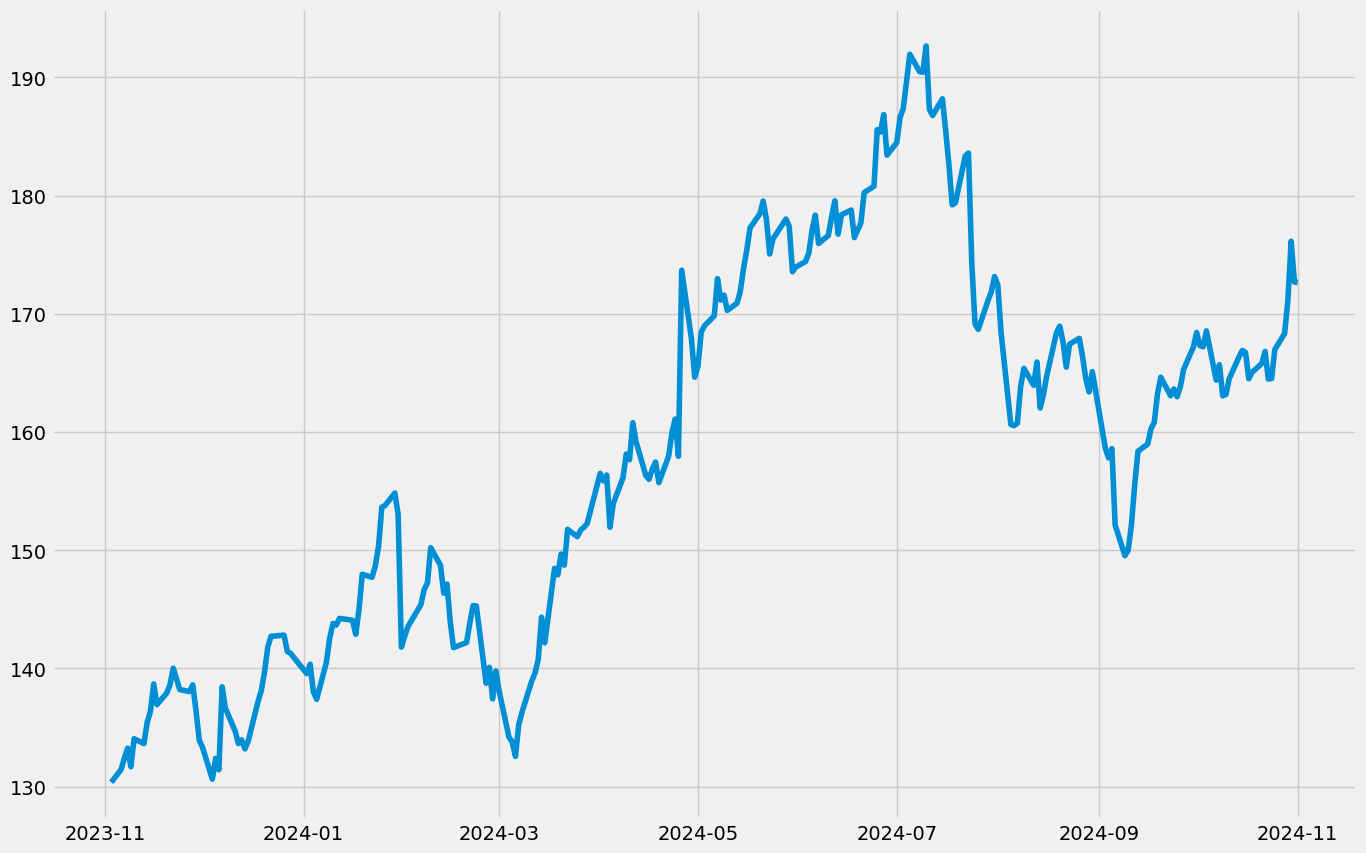

In [8]:
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
plt.figure(figsize=(15, 10))
plt.plot(data["Date"], data["Close"])

In [10]:
p, d, q = 5, 1, 2
from statsmodels.tsa.arima_model import ARIMA
model = ARIMA(data["Close"], order=(p,d,q))  
fitted = model.fit(disp=-1)  
print(fitted.summary())

NotImplementedError: 
statsmodels.tsa.arima_model.ARMA and statsmodels.tsa.arima_model.ARIMA have
been removed in favor of statsmodels.tsa.arima.model.ARIMA (note the .
between arima and model) and statsmodels.tsa.SARIMAX.

statsmodels.tsa.arima.model.ARIMA makes use of the statespace framework and
is both well tested and maintained. It also offers alternative specialized
parameter estimators.


In [11]:
import statsmodels.api as sm
import warnings
model=sm.tsa.statespace.SARIMAX(data['Close'],
                                order=(p, d, q),
                                seasonal_order=(p, d, q, 12))
model=model.fit()
print(model.summary())

 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           15     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  2.42021D+00    |proj g|=  1.56986D-01

At iterate    5    f=  2.32824D+00    |proj g|=  9.41148D-02

At iterate   10    f=  2.29575D+00    |proj g|=  1.99242D-02

At iterate   15    f=  2.29277D+00    |proj g|=  1.36207D-02

At iterate   20    f=  2.29194D+00    |proj g|=  1.03280D-02

At iterate   25    f=  2.28958D+00    |proj g|=  2.65908D-02

At iterate   30    f=  2.28795D+00    |proj g|=  1.35328D-02

At iterate   35    f=  2.28252D+00    |proj g|=  4.80952D-02

At iterate   40    f=  2.27791D+00    |proj g|=  1.01864D-02

At iterate   45    f=  2.27764D+00    |proj g|=  7.93406D-03

At iterate   50    f=  2.27708D+00    |proj g|=  2.10661D-02

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cau

/home/sifa/projects/first/pythonProject/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                                     SARIMAX Results                                      
Dep. Variable:                               GOOG   No. Observations:                  251
Model:             SARIMAX(5, 1, 2)x(5, 1, 2, 12)   Log Likelihood                -571.548
Date:                            Sat, 02 Nov 2024   AIC                           1173.097
Time:                                    22:09:41   BIC                           1225.181
Sample:                                         0   HQIC                          1194.087
                                            - 251                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5895      0.073      8.050      0.000       0.446       0.733
ar.L2         -0.9154      0.092   

Şimdi SARIMA modelini kullanarak önümüzdeki 10 gün için gelecekteki hisse senedi fiyatlarını tahmin edelim:

In [12]:
predictions = model.predict(len(data), len(data)+10)
print(predictions)

251    171.401473
252    171.156101
253    172.435728
254    173.627633
255    173.603216
256    173.365062
257    172.101248
258    171.379172
259    171.531844
260    172.339852
261    172.699991
Name: predicted_mean, dtype: float64


<Axes: >

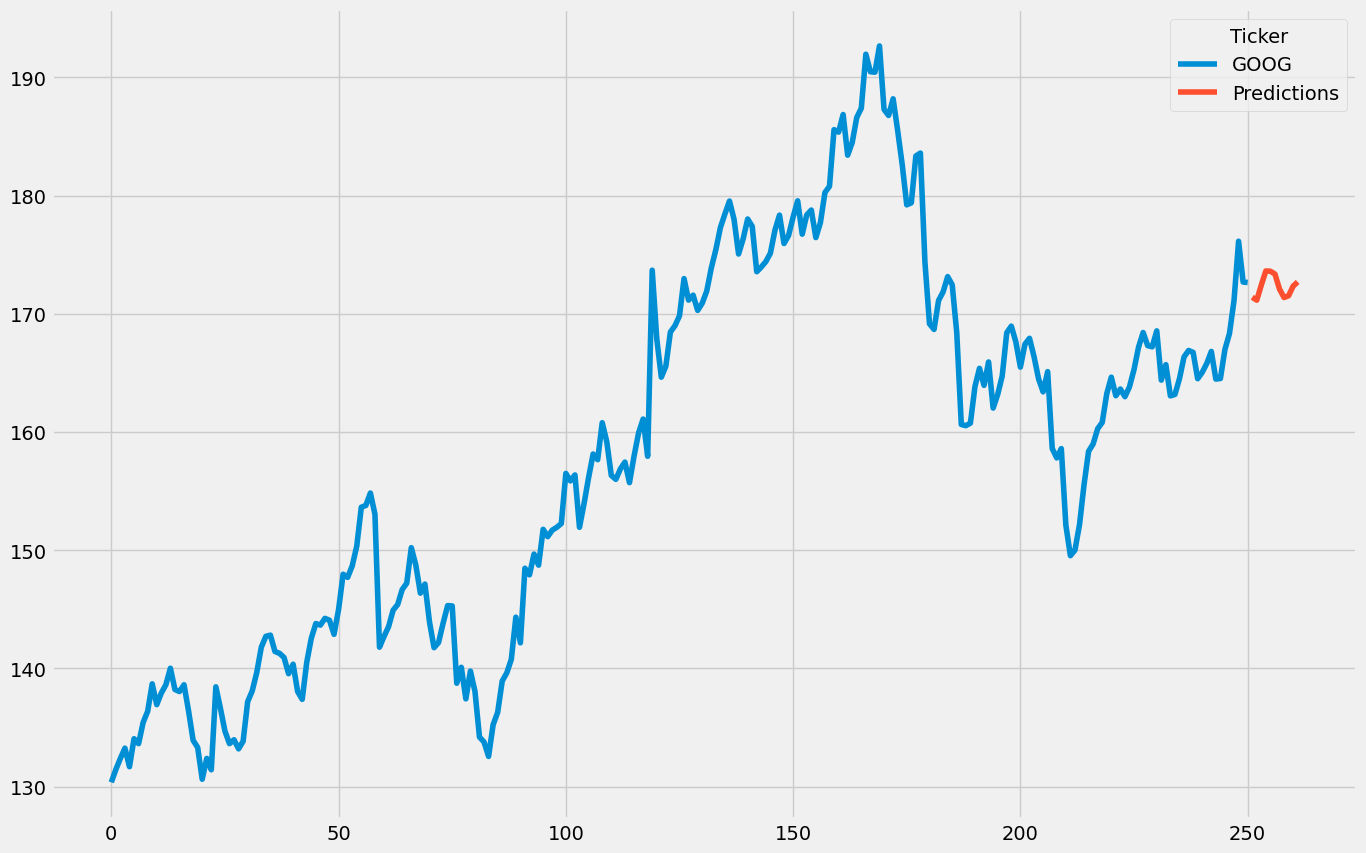

In [13]:
#Tahminleri şu şekilde çizebilirsiniz:
data["Close"].plot(legend=True, label="Training Data", figsize=(15, 10))
predictions.plot(legend=True, label="Predictions")

Özet
ARIMA, Autoregressive Integrated Moving Average (Otoregresif Entegre Hareketli Ortalama) anlamına gelir. Zaman Serisi Verilerini tahmin etmek için kullanılan bir algoritmadır. Veriler durağansa ARIMA'yı, mevsimselse Mevsimsel ARIMA'yı (SARIMA) kullanmamız gerekir.